<a href="https://colab.research.google.com/github/mohithkumarreddyputtur-sketch/DEEP-LEARINING-/blob/main/Experiment_30.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Generated shape: (1000, 784) MSE: 0.017833378 Diversity (mean pair distance): 9.617731


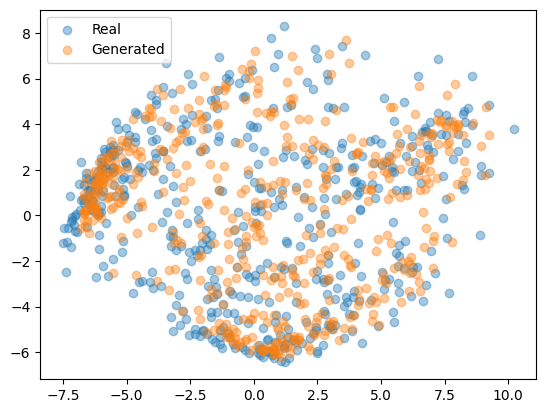

Note: This simplified cell uses reconstruction/diversity proxies, not formal FID or Inception Score.


In [1]:
import tensorflow as tf, numpy as np, matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.metrics import pairwise_distances
(x,y),(xt,yt)=tf.keras.datasets.fashion_mnist.load_data(); x=x[:10000].astype('float32')/255; x=x.reshape(-1,784);
# Use a trained simple decoder as a sample generator (educational comparison substitute)
m=tf.keras.Sequential([tf.keras.layers.Input((784,)),tf.keras.layers.Dense(128,activation='relu'),tf.keras.layers.Dense(784,activation='sigmoid')]); m.compile('adam','mse'); m.fit(x,x,epochs=2,verbose=0)
gen=m.predict(x[:1000],verbose=0); real=x[:1000]
print('Generated shape:',gen.shape,'MSE:',np.mean((real-gen)**2),'Diversity (mean pair distance):',pairwise_distances(gen[:100],metric='euclidean').mean())
p=PCA(2); a=p.fit_transform(real[:500]); b=p.transform(gen[:500]); plt.scatter(a[:,0],a[:,1],alpha=.4,label='Real'); plt.scatter(b[:,0],b[:,1],alpha=.4,label='Generated'); plt.legend(); plt.show()
print('Note: This simplified cell uses reconstruction/diversity proxies, not formal FID or Inception Score.')